# 02 · Hysteresis check (A3)
**Paper:** Ozbudak et al. 2004, *Nature* 427:737 — multistability of the lac operon.
The fitted circuit (`outputs/a3/circuit_model.yaml`) is swept up and down in TMG from both histories (20 h per dose, the paper's
protocol). A bistable switch shows a hysteresis loop; the switching thresholds vs glucose are compared with the paper's Fig. 2c.

In [1]:
import sys, warnings; warnings.filterwarnings('ignore'); sys.path.insert(0, '../src')
import numpy as np, matplotlib.pyplot as plt, yaml
import reaction_network as rn
from build_a3_v3 import FIG2C, sweep, switch_points, hill_coefficient
p = dict(rn.DEFAULT_PARAMS); p.update(yaml.safe_load(open('../outputs/a3/circuit_model.yaml'))['parameters'])
%matplotlib inline
plt.rcParams.update({'figure.facecolor': 'white', 'axes.spines.top': False, 'axes.spines.right': False})

## 1 · Hysteresis loop (no glucose and 1 mM glucose)

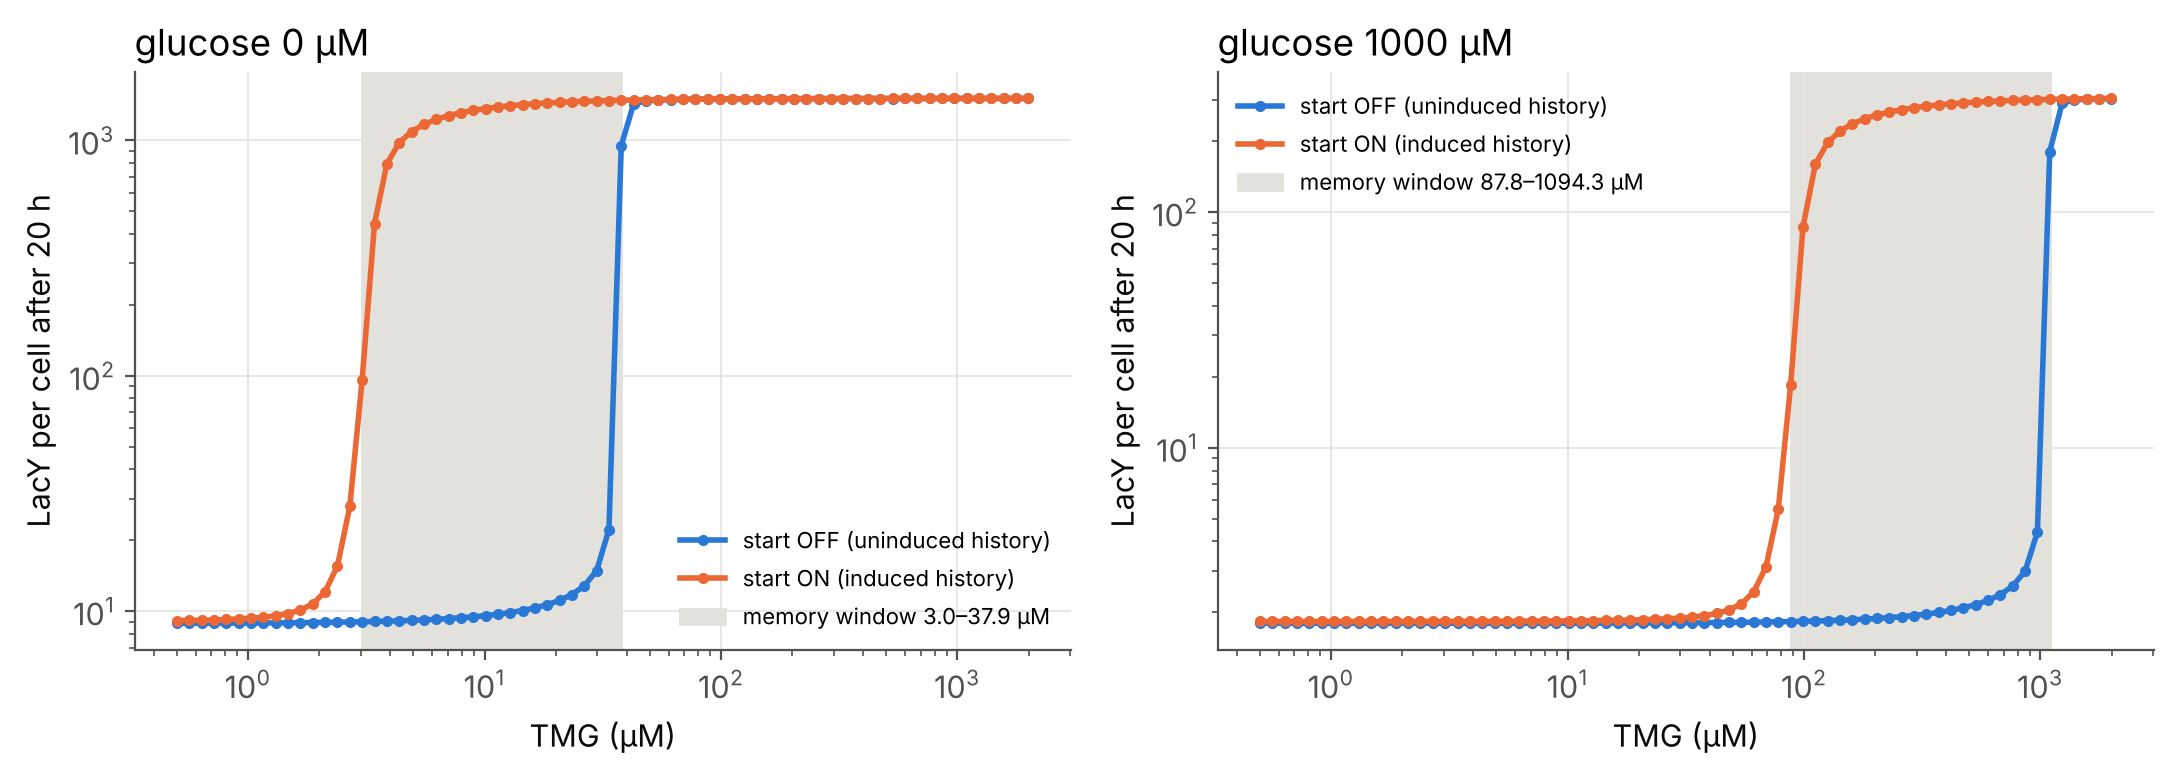

In [2]:
Ts = np.logspace(-0.3, 3.3, 70)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, G in zip(ax, [0.0, 1000.0]):
    up, down = sweep(p, G, Ts)
    off, on = switch_points(Ts, up, down, p, G)
    a.plot(Ts, up, '-o', ms=3, color='#2a78d6', label='start OFF (uninduced history)')
    a.plot(Ts, down, '-o', ms=3, color='#eb6834', label='start ON (induced history)')
    a.axvspan(off, on, color='#e2e1dc', zorder=0, label=f'memory window {off:.1f}–{on:.1f} µM')
    a.set_xscale('log'); a.set_yscale('log'); a.set_xlabel('TMG (µM)'); a.set_ylabel('LacY per cell after 20 h')
    a.set_title(f'glucose {G:g} µM', loc='left'); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 2 · Phase diagram vs Ozbudak Fig. 2c

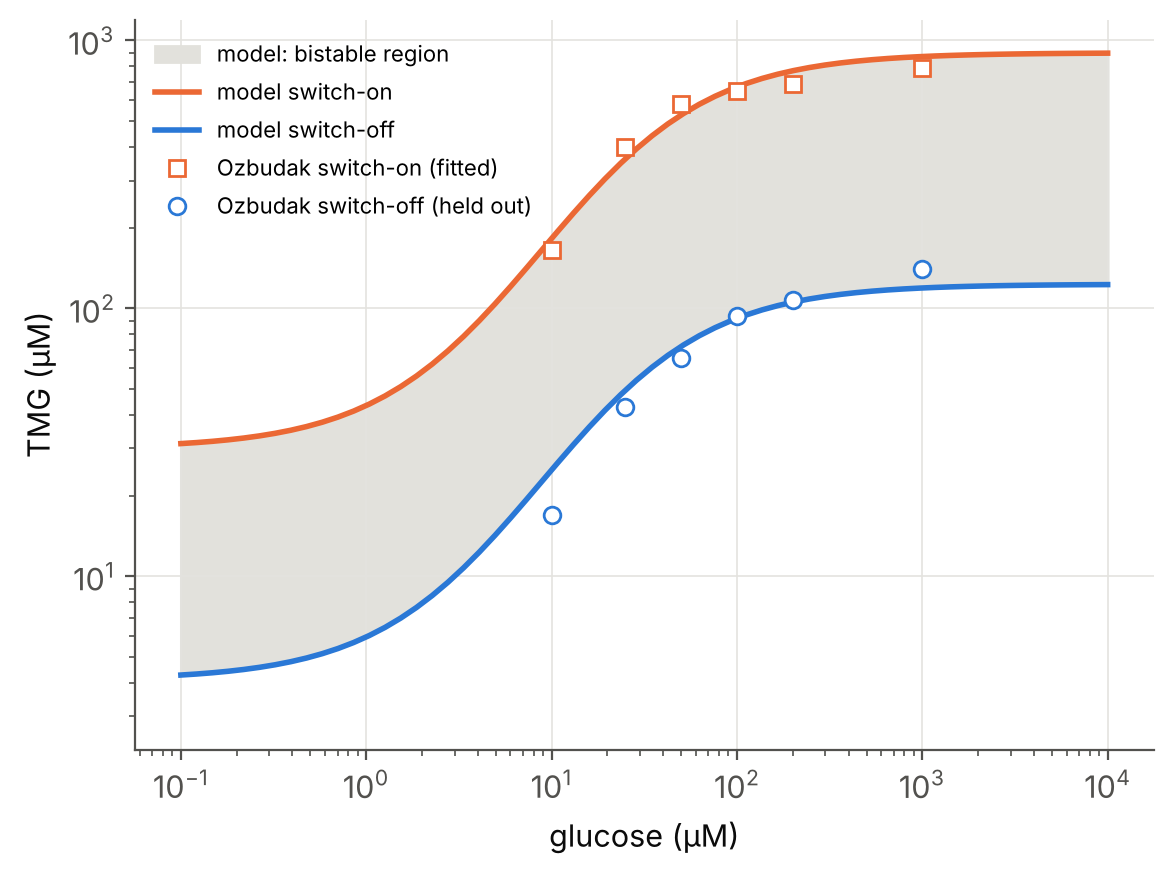

log10 RMSE  switch-on (fitted) 0.037   switch-off (held out) 0.090


In [3]:
G = np.logspace(-1, 4, 60)
th = np.array([rn.thresholds_tmg(g, p) for g in G])
fig, a = plt.subplots(figsize=(6, 4.5))
a.fill_between(G, th[:, 0], th[:, 1], color='#e2e1dc', label='model: bistable region')
a.plot(G, th[:, 1], color='#eb6834', label='model switch-on'); a.plot(G, th[:, 0], color='#2a78d6', label='model switch-off')
a.plot(FIG2C.glucose_uM, FIG2C.switch_on_uM, 's', color='#eb6834', mfc='white', label='Ozbudak switch-on (fitted)')
a.plot(FIG2C.glucose_uM, FIG2C.switch_off_uM, 'o', color='#2a78d6', mfc='white', label='Ozbudak switch-off (held out)')
a.set_xscale('log'); a.set_yscale('log'); a.set_xlabel('glucose (µM)'); a.set_ylabel('TMG (µM)'); a.legend(fontsize=8)
plt.tight_layout(); plt.show()
rm = lambda col, k: float(np.sqrt(np.mean(np.log10(np.array([rn.thresholds_tmg(g, p)[k] for g in FIG2C.glucose_uM]) / FIG2C[col].values) ** 2)))
print(f"log10 RMSE  switch-on (fitted) {rm('switch_on_uM', 1):.3f}   switch-off (held out) {rm('switch_off_uM', 0):.3f}")

## 3 · Operator-decoy strains (ρ = 170, 50, 5) and the cusp

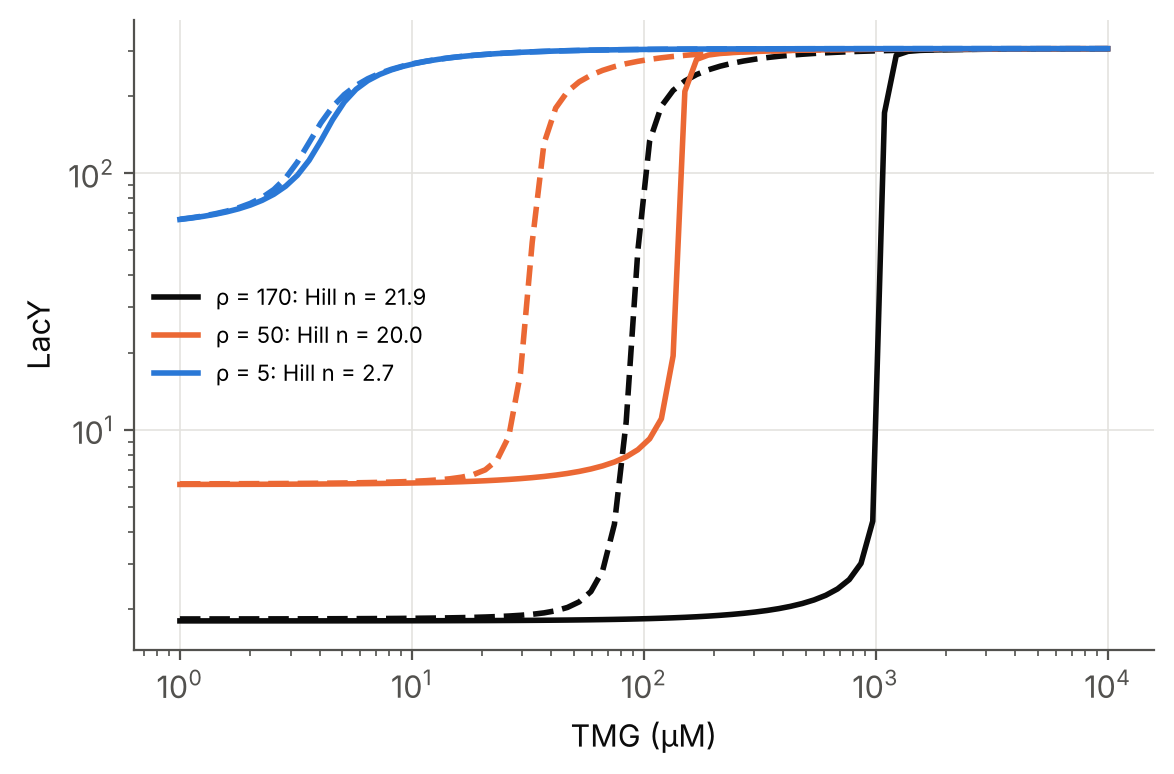

cusp (smallest rho with bistability): 9.01 (theory for n = 2: 9)


In [4]:
Tg = np.logspace(0, 4, 80)
fig, a = plt.subplots(figsize=(6, 4))
for rho, c in [(170, '#0b0b0b'), (50, '#eb6834'), (5, '#2a78d6')]:
    up, down = sweep(p, 1000.0, Tg, rho=rho)
    a.plot(Tg, up, color=c, label=f'ρ = {rho}: Hill n = {hill_coefficient(Tg, up):.1f}'); a.plot(Tg, down, '--', color=c)
a.set_xscale('log'); a.set_yscale('log'); a.set_xlabel('TMG (µM)'); a.set_ylabel('LacY'); a.legend(fontsize=8)
plt.tight_layout(); plt.show()
rhos = np.linspace(5, 15, 1001)
print('cusp (smallest rho with bistability):', rhos[np.argmax([rn.switching_drives(r, p['n']) is not None for r in rhos])], '(theory for n = 2: 9)')

**Reading.** ρ = 170 and 50 give a hysteresis loop (bistable), ρ = 5 a graded response, the cusp sits at ρ ≈ 9 as theory predicts,
and the switch-off line, which was not used in the fit, lands on Ozbudak's data. Known gap: the graded (ρ = 5) response has
Hill n ≈ 2.7 against ≈ 6 in the paper.